<a href="https://colab.research.google.com/github/santidrelew/tp-mpg/blob/main/notebooks/04_Ml_y_Validacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **4 - Machine Learning y Validación**

In [ ]:
try:
    import google.colab
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    !git clone https://github.com/santidrelew/tp-mpg.git
    %cd tp-mpg

Cloning into 'tp-mpg'...
remote: Enumerating objects: 31, done.
remote: Counting objects: 100% (31/31), done.
remote: Compressing objects: 100% (26/26), done.
remote: Total 31 (delta 8), reused 10 (delta 4), pack-reused 0 (from 0)
Receiving objects: 100% (31/31), 2.55 MiB | 7.56 MiB/s, done.
Resolving deltas: 100% (8/8), done.
/content/tp-mpg/tp-mpg


In [ ]:
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import (
    train_test_split,
    cross_validate,
    RandomizedSearchCV,
    StratifiedKFold,
    KFold,
    cross_val_score
)
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    OrdinalEncoder,
    MinMaxScaler,
)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
)
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
)
# Usaremos estas distribuciones para samplear en el RandomSearchCV
from scipy.stats import randint, uniform, loguniform

In [ ]:
# Cargamos los datasets
PROJECT_DIR = Path().resolve() if EN_COLAB else Path().resolve().parent
DATA_BASE_DIR = PROJECT_DIR / "data" / "base"

df = pd.read_csv(DATA_BASE_DIR / "milan_airbnb_completo.csv")
df_muestra = pd.read_csv(DATA_BASE_DIR / "milan_airbnb_muestra.csv")

In [ ]:
TARGET = "log_daily_price"

X, y = df.drop(columns=[TARGET, "daily_price"]), df[TARGET]
X_muestra, y_muestra = df_muestra.drop(columns=[TARGET, "daily_price"]), df_muestra[TARGET]

In [ ]:
X.columns

Index(['host_is_superhost', 'host_total_listings_count',
       'neighbourhood_cleansed', 'latitude', 'longitude', 'accommodates',
       'bathrooms', 'bedrooms', 'beds', 'bed_type', 'guests_included',
       'minimum_nights', 'availability_365', 'number_of_reviews',
       'review_scores_rating', 'TV', 'WiFi', 'Air_Condition',
       'Wheelchair_accessible', 'Kitchen', 'Breakfast', 'Elevator', 'Heating',
       'Washer', 'Iron', 'Host_greets_you', 'Paid_parking_on_premises',
       'Luggage_dropoff_allowed', 'Long_term_stays_allowed', 'Doorman',
       'Pets_allowed', 'Smoking_allowed', 'Suitable_for_events',
       'check_in_24_hour'],
      dtype='object')

Separamos los features en sus respectivas categorias para poder usar un pipeline.


In [ ]:
# 1. Variables numéricas
numeric_features = [
    "host_total_listings_count",
    "latitude",
    "longitude",
    "accommodates",
    "bathrooms",
    "bedrooms",
    "beds",
    "guests_included",
    "minimum_nights",
    "availability_365",
    "number_of_reviews",
    "review_scores_rating"
]

# 2. Variables categóricas nominales
categorical_features = [
    "neighbourhood_cleansed",
    "bed_type"
]

# 3. Variables binarias
binary_features = [
    "host_is_superhost",
    "TV",
    "WiFi",
    "Air_Condition",
    "Wheelchair_accessible",
    "Kitchen",
    "Breakfast",
    "Elevator",
    "Heating",
    "Washer",
    "Iron",
    "Host_greets_you",
    "Paid_parking_on_premises",
    "Luggage_dropoff_allowed",
    "Long_term_stays_allowed",
    "Doorman",
    "Pets_allowed",
    "Smoking_allowed",
    "Suitable_for_events",
    "check_in_24_hour"
]

In [ ]:
# Este preprocesador se aplicará en cada fold del cv para no filtrar datos de
# validación en el entrenamiento, como la media, varianza, etc
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_features),
        ("bin", "passthrough", binary_features)
    ],
    remainder="drop"
)

## 1. Dividimos en train y test

In [ ]:
TEST_SIZE = 0.2
RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

X_train_muestra, X_test_muestra, y_train_muestra, y_test_muestra = train_test_split(
    X_muestra, y_muestra, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

print(f"Total de registros en la base: {df.shape[0]}")
print(f"Registros para ENTRENAR los modelos (X_train): {X_train.shape[0]}")
print(f"Registros para TESTEAR los modelos (X_test): {X_test.shape[0]}")
print(f"Cantidad de variables predictoras: {X_train.shape[1]}")


print("\n============== MUESTRA ==============")
print(f"Total de registros en la base: {df_muestra.shape[0]}")
print(f"Registros para ENTRENAR los modelos (X_train): {X_train_muestra.shape[0]}")
print(f"Registros para TESTEAR los modelos (X_test): {X_test_muestra.shape[0]}")
print(f"Cantidad de variables predictoras: {X_train_muestra.shape[1]}")

Total de registros en la base: 9322
Registros para ENTRENAR los modelos (X_train): 7457
Registros para TESTEAR los modelos (X_test): 1865
Cantidad de variables predictoras: 34

============== MUESTRA ==============
Total de registros en la base: 750
Registros para ENTRENAR los modelos (X_train): 600
Registros para TESTEAR los modelos (X_test): 150
Cantidad de variables predictoras: 34


## 2. Algoritmos e hiperparámetros

In [ ]:
models_and_params = {
    'RandomForest': {
        'model': RandomForestRegressor(random_state=RANDOM_STATE),
        'params': {
            'regressor__n_estimators': randint(100, 500),
            'regressor__max_depth': randint(5, 20),
            'regressor__min_samples_split': randint(2, 10),
            'regressor__min_samples_leaf': randint(1, 5),
        }
    },
    'GradientBoosting': {
        'model': GradientBoostingRegressor(random_state=RANDOM_STATE),
        'params': {
            'regressor__n_estimators': randint(100, 500),
            'regressor__learning_rate': loguniform(0.01, 0.3),
            'regressor__max_depth': randint(3, 10),
            'regressor__subsample': uniform(0.6, 0.4),
        }
    },
    'KNN': {
        'model': KNeighborsRegressor(),
        'params': {
            'regressor__n_neighbors': randint(3, 20),
            'regressor__weights': ['uniform', 'distance'],
            'regressor__p': [1, 2],
        }
    },
}

In [ ]:
def random_search_cv(X, y, modelo, parametros, n_iter, scoring):

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", modelo)
    ])

    # Antes de entrenar mezclamos las observaciones para hacer separar los folds
    cv = KFold(
        n_splits=5,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    metricas = {
        "MAE": "neg_mean_absolute_error",
        "MSE": "neg_mean_squared_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    }

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=parametros,
        n_iter=n_iter,
        scoring=metricas, # esto hace calcule las métricas del mejor modelo en cada fold
        refit=scoring, # esto hace que elija el mejor modelo segun el scoring
        cv=cv,
        n_jobs=-1,
        random_state=RANDOM_STATE
    )

    search.fit(X, y)

    # Devolvemos las métricas de cada conjunto de validación
    best_idx = search.best_index_ # indice de la mejor muestra de hiperparametros

    metricas_folds = []

    for fold in range(cv.get_n_splits()):
        metricas_folds.append({
            "Fold": fold + 1,
            "MAE": -search.cv_results_[f"split{fold}_test_MAE"][best_idx],
            "MSE": -search.cv_results_[f"split{fold}_test_MSE"][best_idx],
            "RMSE": -search.cv_results_[f"split{fold}_test_RMSE"][best_idx],
            "R2": search.cv_results_[f"split{fold}_test_R2"][best_idx]
        })

    df_metricas = pd.DataFrame(metricas_folds).set_index("Fold")
    display(df_metricas)

    return {"hyperparams": search.best_params_, "metricas": df_metricas}


In [ ]:
resultados = {}

for nombre, config in models_and_params.items():

    print(f"{'='*15} {nombre} {'='*15}")

    resultados[nombre] = random_search_cv(
        X=X_muestra,
        y=y_muestra,
        modelo=config["model"],
        parametros=config["params"],
        n_iter=2,
        scoring="MSE"
    )


=============== RandomForest ===============


,MAE,MSE,RMSE,R2
Fold,,,,
1,0.240610,0.115247,0.339480,0.520614
2,0.376725,0.340292,0.583346,0.218642
3,0.296751,0.151485,0.389210,0.463591
4,0.258147,0.108671,0.329653,0.540889
5,0.278488,0.174539,0.417778,0.337550


=============== GradientBoosting ===============


,MAE,MSE,RMSE,R2
Fold,,,,
1,0.245622,0.126366,0.355479,0.474363
2,0.376717,0.357205,0.597666,0.179808
3,0.310604,0.162249,0.402802,0.425474
4,0.275906,0.134360,0.366552,0.432358
5,0.278199,0.179976,0.424236,0.316912


=============== KNN ===============


,MAE,MSE,RMSE,R2
Fold,,,,
1,0.287766,0.141053,0.375571,0.413267
2,0.386205,0.344029,0.586540,0.210063
3,0.324351,0.178211,0.422151,0.368953
4,0.321977,0.168114,0.410017,0.289755
5,0.314727,0.212254,0.460711,0.194403


 Veamos estos resultados en boxplots para que sea mas facil de visualizar

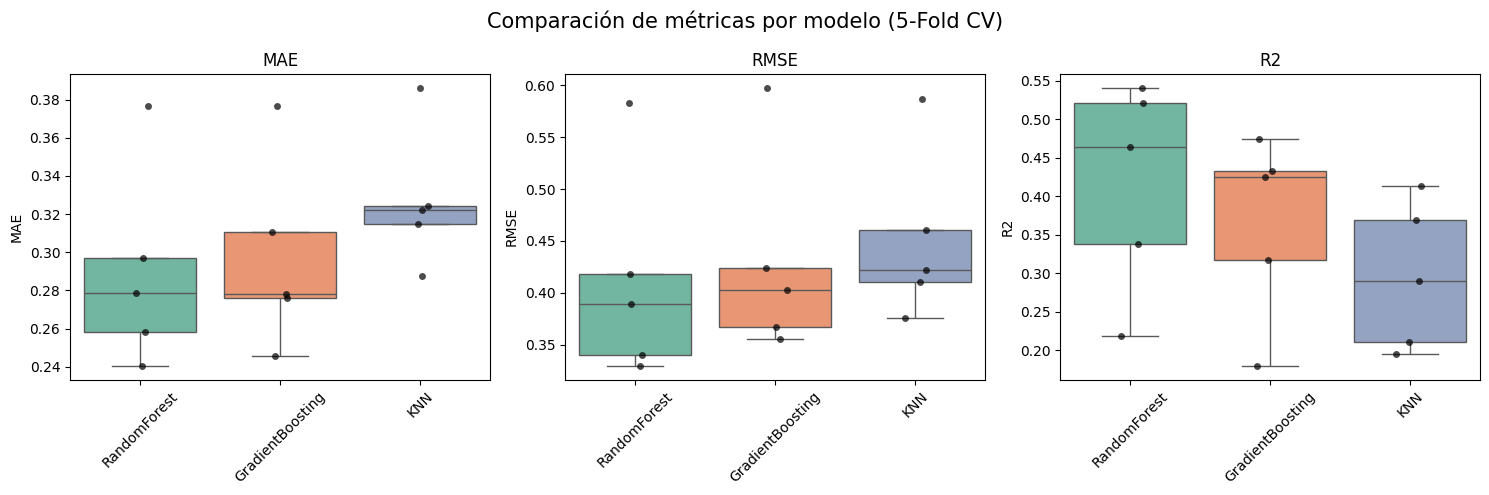

In [ ]:
# Unificamos resultados en un solo dataframe
filas = []

for modelo, res in resultados.items():
    df = res["metricas"].copy().reset_index()   # recupera Fold como columna
    df["Modelo"] = modelo
    filas.append(df)

df_comparativo = pd.concat(filas, ignore_index=True)

metricas = ["MAE", "RMSE", "R2"]

modelos = df_comparativo["Modelo"].unique()

# Un color fijo por modelo
palette = dict(zip(modelos, sns.color_palette("Set2", n_colors=len(modelos))))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, metrica in zip(axes, metricas):

    sns.boxplot(
        data=df_comparativo,
        x="Modelo",
        y=metrica,
        hue="Modelo",
        order=modelos,
        hue_order=modelos,
        palette=palette,
        dodge=False,
        showfliers=False,
        legend=False,
        ax=ax
    )

    sns.stripplot(
        data=df_comparativo,
        x="Modelo",
        y=metrica,
        order=modelos,
        color="black",
        alpha=0.7,
        jitter=True,
        size=5,
        ax=ax
    )

    ax.set_title(metrica)
    ax.set_xlabel("")
    ax.set_ylabel(metrica)
    ax.tick_params(axis="x", rotation=45)

fig.suptitle("Comparación de métricas por modelo (5-Fold CV)", fontsize=15)
plt.tight_layout()
plt.show()

In [ ]:
mejor_modelo = "RandomForest"
mejores_hyperparametros = {hiper.split("__")[1]: valor for hiper, valor in resultados[mejor_modelo]["hyperparams"].items()}

# Ajustamos el modelo
pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(random_state=RANDOM_STATE, **mejores_hyperparametros))
])

final_model = pipeline.fit(X_train, y_train)

# Metricas de entrenamiento
print("Metricas de entrenamiento")
y_pred_train = final_model.predict(X_train)
print(f"MAE: {mean_absolute_error(y_train, y_pred_train)}")
print(f"MSE: {mean_squared_error(y_train, y_pred_train)}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_train, y_pred_train))}")
print(f"R2: {r2_score(y_train, y_pred_train)}")

# Evaluación final
y_pred = final_model.predict(X_test)

print("\nMetricas de test")
print(f"MAE: {mean_absolute_error(y_test, y_pred)}")
print(f"MSE: {mean_squared_error(y_test, y_pred)}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred))}")
print(f"R2: {r2_score(y_test, y_pred)}")

Metricas de entrenamiento
MAE: 0.2188185399900428
MSE: 0.09605279290975417
RMSE: 0.309923850178966
R2: 0.6760184939196754

Metricas de test
MAE: 0.2876326374072571
MSE: 0.19158338687112986
RMSE: 0.4377023953225866
R2: 0.4281606022918951


## Validación con la base filtrada y la selección del EDA

Usamos los predictores seleccionados en el EDA. La partición y la búsqueda de hiperparámetros se mantienen para comparar los resultados.

### 1. Carga de datos

In [ ]:
from sklearn.base import clone
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score

df_ml = pd.read_csv(DATA_BASE_DIR / "milan_airbnb_completo_filtrado.csv")
X = df_ml.drop(columns=["daily_price", "log_daily_price"])
y = df_ml["log_daily_price"]

### 2. División en entrenamiento y prueba

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

### 3. Preprocesamiento y algoritmos

In [ ]:
preparador = ColumnTransformer([
    ("num", StandardScaler(), [col for col in numeric_features if col in X.columns]),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), [col for col in categorical_features if col in X.columns]),
    ("bin", "passthrough", [col for col in binary_features if col in X.columns]),
], remainder="drop")

candidatos = {"OLS": {"model": LinearRegression()}, **models_and_params}

### 4. Validación cruzada en entrenamiento

In [ ]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
ajustes = {}

for nombre, config in candidatos.items():
    pipeline = Pipeline([
        ("preprocessor", clone(preparador)),
        ("regressor", clone(config["model"])),
    ])
    if "params" in config:
        ajuste = RandomizedSearchCV(
            pipeline, param_distributions=config["params"],
            n_iter=12, scoring="neg_mean_squared_error",
            cv=cv, n_jobs=-1, random_state=42,
        ).fit(X_train, y_train)
        rmse_cv = (-ajuste.best_score_)**0.5
    else:
        scores = cross_val_score(
            pipeline, X_train, y_train, scoring="neg_mean_squared_error", cv=cv
        )
        rmse_cv = (-scores.mean())**0.5
        ajuste = pipeline.fit(X_train, y_train)
    ajustes[nombre] = (ajuste, rmse_cv)

### 5. Evaluación en el test común

In [ ]:
filas = []
for nombre, (ajuste, rmse_cv) in ajustes.items():
    pred_train = ajuste.predict(X_train)
    pred_test = ajuste.predict(X_test)
    mse_test = mean_squared_error(y_test, pred_test)
    filas.append({
        "Modelo": nombre,
        "RMSE CV": rmse_cv,
        "RMSE train": mean_squared_error(y_train, pred_train)**0.5,
        "MAE test": mean_absolute_error(y_test, pred_test),
        "MSE test": mse_test,
        "RMSE test": mse_test**0.5,
        "R² test": r2_score(y_test, pred_test),
    })

resultados_filtrados = pd.DataFrame(filas).sort_values("RMSE CV")
display(resultados_filtrados.round(4))

,Modelo,RMSE CV,RMSE train,MAE test,MSE test,RMSE test,R² test
2,GradientBoosting,0.3901,0.3095,0.2594,0.1419,0.3767,0.5213
1,RandomForest,0.4011,0.2373,0.2721,0.1560,0.3949,0.4740
3,KNN,0.4200,0.0000,0.2978,0.1751,0.4184,0.4095
0,OLS,0.4327,0.4302,0.2985,0.1758,0.4192,0.4072


La comparación utiliza el RMSE de validación cruzada y evalúa los modelos en el mismo test.

Con la selección del EDA, **GradientBoosting** obtuvo el menor RMSE de validación cruzada (0.3901) y un RMSE en prueba de 0.3767. Su RMSE en entrenamiento fue 0.3095. Antes de aplicar los seis descartes, Gradient Boosting obtuvo 0,3894 en validación cruzada y 0,3765 en prueba. Los errores se expresan en escala de log-precio.